In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 



df = pd.read_csv('Student_Social_Media_And_Mental_Health_Impact.csv')
# print(df.head())
# print(df.describe())




<Axes: xlabel='Most_Used_Platform', ylabel='count'>

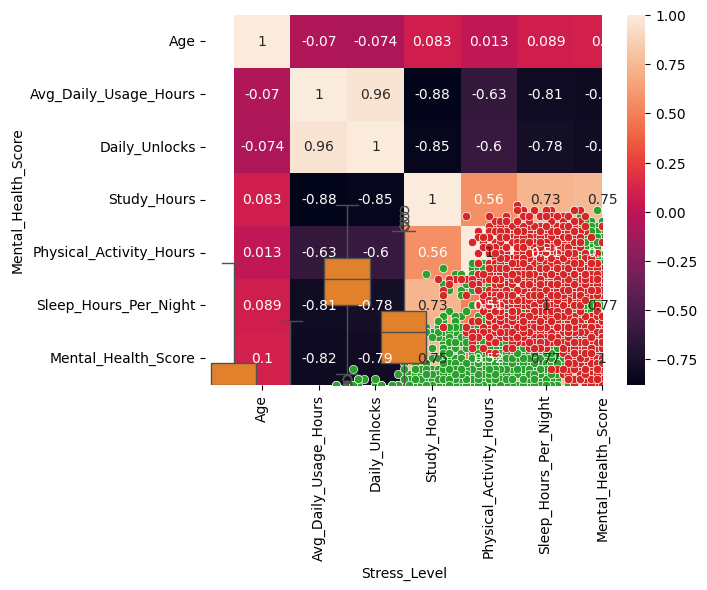

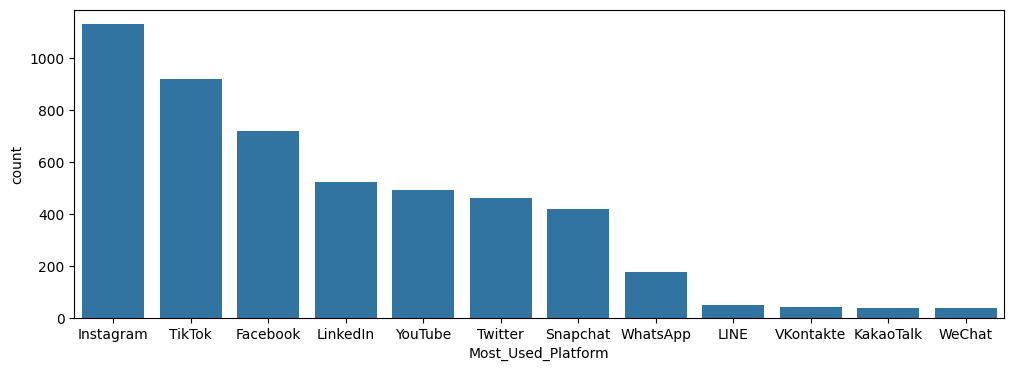

In [13]:

sns.histplot(df['Mental_Health_Score'],kde=True)
sns.heatmap(df.corr(numeric_only=True),annot = True)
df['Stress_Level'].unique()

sns.boxplot( x ='Stress_Level', y = 'Mental_Health_Score',data = df )

sns.scatterplot(x = 'Avg_Daily_Usage_Hours',y = 'Mental_Health_Score',data = df)

sns.scatterplot(x = 'Sleep_Hours_Per_Night',y = 'Mental_Health_Score',data = df)

plt.figure(figsize = (12,4))
sns.countplot(x = df['Most_Used_Platform'] ,order = df['Most_Used_Platform'].value_counts().index)


In [14]:

num_features = df.select_dtypes(include=['number'])
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)

IQR  = Q3-Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
outliers = (num_features < lower_bound )| (num_features > upper_bound)
outliers.sum()


Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64

In [ ]:

df.drop_duplicates()


df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower = 0)
top_countries = df['Country'].value_counts().index[:10].tolist()
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

df['grouped_country'] = df['Country'].apply(group_countries)
# print(df['grouped_country'].value_counts())


skewed_col = ['Study_Hours']
other_numeric_cols = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Physical_Activity_Hours','Sleep_Hours_Per_Night']
ordinal_cols = ['Stress_Level']
normal_cols =  ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "grouped_country"]


feature_col = skewed_col + other_numeric_cols + ordinal_cols + normal_cols 


In [29]:
df['Stress_Level'].unique()

<ArrowStringArray>
['Medium', 'Low', 'Very High', 'High']
Length: 4, dtype: str

In [16]:

# TRAIN TEST SPLIT
X,y  = df[feature_col] ,df['Mental_Health_Score'] 

from sklearn.model_selection import train_test_split
X_train ,x_test , y_train , y_test = train_test_split(X, y,test_size=0.30 , random_state=42)


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder , OneHotEncoder 
from sklearn.compose import ColumnTransformer

skew_pipeline = Pipeline(steps = [('log_transform',FunctionTransformer(np.log1p)),('scale',StandardScaler())])

plain_numeric_pipeline = Pipeline(steps = [('scale',StandardScaler())])

ordinal_pipeline = Pipeline(steps = [('encode',OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
])

normal_pipeline = Pipeline(steps = [('encode',OneHotEncoder(handle_unknown='ignore'
))])



preprocessor = ColumnTransformer(transformers=[("Skewed_Pipeline",skew_pipeline,skewed_col),
("Numeric_Pipline",plain_numeric_pipeline,other_numeric_cols),
("Ordinal_Pipeline",ordinal_pipeline,ordinal_cols),
("Normal_Pipeline",normal_pipeline,normal_cols)])


In [17]:


# Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

lr_pipline = Pipeline(steps=[('preprocessr',preprocessor),
('regression',LinearRegression())])

lr_pipline.fit(X_train,y_train)
lr_pred = lr_pipline.predict(x_test)
lr_pred_train = lr_pipline.predict(X_train)

lr_test_r2= r2_score(y_test,lr_pred)
# 0.7561861365384527
lr_train_r2= r2_score(y_train,lr_pred_train)
# 0.7181441215388289
lr_mae = mean_absolute_error(y_test,lr_pred)
# 0.5131589482163136
lr_rmse = np.sqrt(lr_mae)


In [18]:

# RANDOM FOREST 
from sklearn.ensemble import RandomForestRegressor
rf_pipeline = Pipeline(steps=[('preprocessor',preprocessor),('random forest',RandomForestRegressor(random_state=42))])

rf_pipeline.fit(X_train,y_train)
rf_pred = rf_pipeline.predict(x_test)
rf_pred_training = rf_pipeline.predict(X_train)

rf_r2_test = r2_score(y_test,rf_pred)
rf_r2_train = r2_score(y_train,rf_pred_training)
rf_mae = mean_absolute_error(y_test,rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test,rf_pred))

# 0.8818461232863266
# 0.9814631430179235
# 0.33955020000000014



In [19]:

# HYPER PERAMETER TUNING 

from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'       : [100,200,300],
    'random forest__max_depth'         : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf'  : [1,2,4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter = 15,
    cv = 5,
    scoring='r2',
    random_state=42,
    n_jobs =-1 #processor free
)

random_search.fit(X_train, y_train)


# print(random_search.best_params_)


rf_best_pipeline = random_search.best_estimator_
rf_best_preds = rf_best_pipeline.predict(x_test)

r2_best_rf = r2_score(y_test,rf_best_preds)
mar_best_rf = mean_absolute_error(y_test,rf_best_preds)
# 0.8695530281264361
# 0.3600452452782747


In [20]:

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(x_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_test_r2, rf_r2_test, rf_tuned_r2],
    'Training R2': [lr_test_r2, rf_r2_train, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

# print(results)
#                      Model        R2  Training R2       MAE      RMSE
# 0        Linear Regression  0.752973     0.752973  0.513159  0.716351
# 1  Random Forest (default)  0.881846     0.981463  0.339550  0.451897
# 2    Random Forest (tuned)  0.869553     0.956682  0.360045  0.474824


In [21]:

import joblib
joblib.dump(rf_pipeline,'Mansik_santulant.pkl')

['Mansik_santulant.pkl']

In [22]:
df.columns.tolist()

['Age',
 'Gender',
 'Country',
 'Academic_Level',
 'Most_Used_Platform',
 'Purpose_Of_Use',
 'Avg_Daily_Usage_Hours',
 'Daily_Unlocks',
 'Study_Hours',
 'Physical_Activity_Hours',
 'Sleep_Hours_Per_Night',
 'Stress_Level',
 'Mental_Health_Score',
 'grouped_country']

In [23]:
import sklearn
print(sklearn.__version__)

1.9.1
